In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from copy import deepcopy
import random
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import optuna
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

In [2]:
PROJECT_ROOT = Path.cwd().parent
MODELING_DATA_DIR = PROJECT_ROOT / "data" / "processed" / "modeling"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

X_train = joblib.load(MODELING_DATA_DIR / "X_train_target_diag.joblib")
X_val = joblib.load(MODELING_DATA_DIR / "X_val_target_diag.joblib")
X_test = joblib.load(MODELING_DATA_DIR / "X_test_target_diag.joblib")

y_train = joblib.load(MODELING_DATA_DIR / "y_train.joblib")
y_val = joblib.load(MODELING_DATA_DIR / "y_val.joblib")
y_test = joblib.load(MODELING_DATA_DIR / "y_test.joblib")

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


U ovom delu se ponovo koriste ista priprema podataka, definicija MLP arhitekture i pomocne funkcije kao u notebook-u 05_mlp_modeling, kako bi optimizovani model bio direktno uporediv sa osnovnim MLP modelom.

In [4]:
X_train = torch.tensor(X_train.toarray(), dtype=torch.float32)
X_val = torch.tensor(X_val.toarray(), dtype=torch.float32)
X_test = torch.tensor(X_test.toarray(), dtype=torch.float32)

y_train = torch.tensor(np.asarray(y_train), dtype=torch.float32).view(-1, 1)
y_val = torch.tensor(np.asarray(y_val), dtype=torch.float32).view(-1, 1)
y_test = torch.tensor(np.asarray(y_test), dtype=torch.float32).view(-1, 1)

In [5]:
train_dataset = TensorDataset(
    X_train,
    y_train
)

val_dataset = TensorDataset(
    X_val,
    y_val
)

test_dataset = TensorDataset(
    X_test,
    y_test
)

In [6]:
class MLP(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dims,
        bottleneck_dim,
        dropout=0.0
    ):
        super().__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dims[0])
        self.fc2 = nn.Linear(hidden_dims[0], hidden_dims[1])
        self.bottleneck = nn.Linear(
            hidden_dims[1],
            bottleneck_dim
        )
        self.output = nn.Linear(bottleneck_dim, 1)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.relu(self.bottleneck(x))

        logits = self.output(x)

        return logits

In [7]:
num_positive = y_train.sum()
num_negative = len(y_train) - num_positive

pos_weight = num_negative / num_positive

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight.to(device)
)

In [8]:
def train_one_epoch(model, data_loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0

    for X_batch, y_batch in data_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    average_loss = total_loss / len(data_loader.dataset)

    return average_loss

In [9]:
def evaluate(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in data_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)

            loss = criterion(logits, y_batch)

            total_loss += loss.item() * X_batch.size(0)

    average_loss = total_loss / len(data_loader.dataset)

    return average_loss

In [10]:
def predict_probabilities(model, data_loader, device):
    model.eval()

    y_true = []
    y_prob = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)

            logits = model(X_batch)
            probabilities = torch.sigmoid(logits)

            y_true.extend(y_batch.numpy().flatten())
            y_prob.extend(probabilities.cpu().numpy().flatten())

    return np.array(y_true), np.array(y_prob)

---

Optimizacija hiperparametara. <br>
Definisemo ciljnu funkciju koju Optuna izvrsava tokom svakog pokusaja optimizacije. <br>
Nasumicno se bira kombinacija hiperparametara, formira se i trenira novi model. Nakon treninga model se evaluira na validacionom skupu, a f1 score je ciljna funkcija koju Optuna maksimizuje prilikom izbora najbolje kombinacije hiperparametara. <br>
<br>
hidden_dims - broj neurona u skrivenim slojevima.<br>
bottleneck_dim - velicina bottleneck sloja.<br>
dropout - procenat nasumicno izbacenih neurona kako model ne bi overfit-ovao.<br>
learning rate - za azuriranje tezina. <br>
batch_size - broj uzoraka u batch-u. <br>
patience - broj epoha bez poboljsanja greske nakon kojih se aktivira early stopping.

In [11]:
def objective(trial):

    architecture = trial.suggest_categorical(
        "architecture",
        [
            "64_32",
            "128_64",
            "256_128"
        ]
    )

    architectures = {
        "64_32": [64, 32],
        "128_64": [128, 64],
        "256_128": [256, 128]
    }

    hidden_dims = architectures[architecture]

    bottleneck_dim = trial.suggest_categorical(
        "bottleneck_dim",
        [8, 16, 32]
    )

    dropout = trial.suggest_categorical(
        "dropout",
        [0.0, 0.2, 0.3, 0.5]
    )

    learning_rate = trial.suggest_categorical(
        "learning_rate",
        [0.0005, 0.001, 0.003]
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [128, 256, 512]
    )

    patience = trial.suggest_categorical(
        "patience",
        [5, 10]
    )

    trial_train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    trial_val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    trial_model = MLP(
        input_dim=X_train.shape[1],
        hidden_dims=hidden_dims,
        bottleneck_dim=bottleneck_dim,
        dropout=dropout
    ).to(device)

    trial_optimizer = torch.optim.Adam(
        trial_model.parameters(),
        lr=learning_rate
    )

    num_epochs = 50

    best_val_loss = float("inf")
    best_model_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(num_epochs):

        train_one_epoch(
            model=trial_model,
            data_loader=trial_train_loader,
            criterion=criterion,
            optimizer=trial_optimizer,
            device=device
        )

        val_loss = evaluate(
            model=trial_model,
            data_loader=trial_val_loader,
            criterion=criterion,
            device=device
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = deepcopy(
                trial_model.state_dict()
            )
            best_epoch = epoch + 1
            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    trial_model.load_state_dict(
        best_model_state
    )

    y_val_true, y_val_prob = predict_probabilities(
        model=trial_model,
        data_loader=trial_val_loader,
        device=device
    )

    y_val_pred = (
        y_val_prob >= 0.5
    ).astype(int)

    validation_f1 = f1_score(
        y_val_true,
        y_val_pred,
        zero_division=0
    )

    trial.set_user_attr(
        "best_epoch",
        best_epoch
    )

    trial.set_user_attr(
        "best_val_loss",
        float(best_val_loss)
    )

    return float(validation_f1)


Pokretanje optimizacije.

In [12]:
study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)

[I 2026-07-23 09:02:09,104] A new study created in memory with name: no-name-36c8be03-f1ef-4306-85f5-dab0b278e11b
[I 2026-07-23 09:02:34,998] Trial 0 finished with value: 0.2716049382716049 and parameters: {'architecture': '64_32', 'bottleneck_dim': 8, 'dropout': 0.3, 'learning_rate': 0.003, 'batch_size': 128, 'patience': 10}. Best is trial 0 with value: 0.2716049382716049.
[I 2026-07-23 09:02:47,483] Trial 1 finished with value: 0.27957433619175537 and parameters: {'architecture': '64_32', 'bottleneck_dim': 16, 'dropout': 0.2, 'learning_rate': 0.0005, 'batch_size': 256, 'patience': 10}. Best is trial 1 with value: 0.27957433619175537.
[I 2026-07-23 09:02:54,781] Trial 2 finished with value: 0.27008888082713584 and parameters: {'architecture': '64_32', 'bottleneck_dim': 32, 'dropout': 0.2, 'learning_rate': 0.003, 'batch_size': 256, 'patience': 5}. Best is trial 1 with value: 0.27957433619175537.
[I 2026-07-23 09:03:00,494] Trial 3 finished with value: 0.2679583257174191 and parameters:

In [13]:
best_trial = study.best_trial

print(f"Best trial: {best_trial.number}")
print(f"Best validation F1-score: {best_trial.value:.4f}")
print(
    f"Best validation loss: "
    f"{best_trial.user_attrs['best_val_loss']:.4f}"
)

print(
    f"Best epoch: "
    f"{best_trial.user_attrs['best_epoch']}"
)

print("\nBest hyperparameters:")

for parameter, value in best_trial.params.items():
    print(f"{parameter}: {value}")

Best trial: 7
Best validation F1-score: 0.2873
Best validation loss: 1.1423
Best epoch: 5

Best hyperparameters:
architecture: 256_128
bottleneck_dim: 16
dropout: 0.0
learning_rate: 0.003
batch_size: 128
patience: 5


In [14]:
optuna_results = study.trials_dataframe()

optuna_results = optuna_results.sort_values(
    by="value",
    ascending=False
)

optuna_results.head(10)

,number,value,datetime_start,datetime_complete,duration,params_architecture,params_batch_size,params_bottleneck_dim,params_dropout,params_learning_rate,params_patience,user_attrs_best_epoch,user_attrs_best_val_loss,state
7,7,0.287343,2026-07-23 09:03:30.936099,2026-07-23 09:03:45.604537,0 days 00:00:14.668438,256_128,128,16,0.0,0.0030,5,5,1.142324,COMPLETE
10,10,0.283871,2026-07-23 09:04:16.204652,2026-07-23 09:04:31.652520,0 days 00:00:15.447868,256_128,128,16,0.5,0.0010,5,5,1.139776,COMPLETE
17,17,0.283047,2026-07-23 09:06:06.110412,2026-07-23 09:06:18.384298,0 days 00:00:12.273886,256_128,128,16,0.0,0.0010,5,4,1.142913,COMPLETE
13,13,0.282654,2026-07-23 09:05:02.914664,2026-07-23 09:05:14.067622,0 days 00:00:11.152958,256_128,128,16,0.0,0.0010,5,2,1.144528,COMPLETE
20,20,0.282345,2026-07-23 09:06:44.027295,2026-07-23 09:06:54.445425,0 days 00:00:10.418130,256_128,128,16,0.0,0.0030,5,2,1.143182,COMPLETE
27,27,0.281785,2026-07-23 09:08:14.874254,2026-07-23 09:08:29.925645,0 days 00:00:15.051391,256_128,128,16,0.5,0.0010,5,5,1.141496,COMPLETE
28,28,0.281641,2026-07-23 09:08:29.926655,2026-07-23 09:08:44.472082,0 days 00:00:14.545427,64_32,256,8,0.3,0.0010,5,9,1.141078,COMPLETE
9,9,0.281527,2026-07-23 09:04:01.054814,2026-07-23 09:04:16.203651,0 days 00:00:15.148837,128_64,256,8,0.0,0.0005,10,5,1.140173,COMPLETE
1,1,0.279574,2026-07-23 09:02:34.998697,2026-07-23 09:02:47.483397,0 days 00:00:12.484700,64_32,256,16,0.2,0.0005,10,7,1.139817,COMPLETE
12,12,0.279563,2026-07-23 09:04:43.819666,2026-07-23 09:05:02.912655,0 days 00:00:19.092989,256_128,128,16,0.5,0.0010,5,8,1.142731,COMPLETE


In [15]:
optuna_results.to_csv(
    TABLES_DIR / "mlp_optuna_results.csv",
    index=False
)

Konacni optimizovani model sa hiperparametrima.

In [16]:
best_architectures = {
    "64_32": [64, 32],
    "128_64": [128, 64],
    "256_128": [256, 128]
}

best_hidden_dims = best_architectures[
    study.best_params["architecture"]
]

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

best_model = MLP(
    input_dim=X_train.shape[1],
    hidden_dims=best_hidden_dims,
    bottleneck_dim=study.best_params["bottleneck_dim"],
    dropout=study.best_params["dropout"]
).to(device)

best_optimizer = torch.optim.Adam(
    best_model.parameters(),
    lr=study.best_params["learning_rate"]
)


In [17]:
best_batch_size = study.best_params["batch_size"]

optimized_train_loader = DataLoader(
    train_dataset,
    batch_size=best_batch_size,
    shuffle=True
)

optimized_val_loader = DataLoader(
    val_dataset,
    batch_size=best_batch_size,
    shuffle=False
)

optimized_test_loader = DataLoader(
    test_dataset,
    batch_size=best_batch_size,
    shuffle=False
)

Trening optimizovanog modela.

In [18]:
num_epochs = 50
patience = study.best_params["patience"]

best_train_losses = []
best_val_losses = []

best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        model=best_model,
        data_loader=optimized_train_loader,
        criterion=criterion,
        optimizer=best_optimizer,
        device=device
    )

    val_loss = evaluate(
        model=best_model,
        data_loader=optimized_val_loader,
        criterion=criterion,
        device=device
    )

    best_train_losses.append(train_loss)
    best_val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            best_model.state_dict(),
            MODEL_DIR / "optimized_mlp_model.pt"
        )

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

Epoch 1/50 | Train loss: 1.1652 | Validation loss: 1.1460
Epoch 2/50 | Train loss: 1.1496 | Validation loss: 1.1439
Epoch 3/50 | Train loss: 1.1447 | Validation loss: 1.1489
Epoch 4/50 | Train loss: 1.1371 | Validation loss: 1.1640
Epoch 5/50 | Train loss: 1.1315 | Validation loss: 1.1533
Epoch 6/50 | Train loss: 1.1249 | Validation loss: 1.1502
Epoch 7/50 | Train loss: 1.1186 | Validation loss: 1.1521
Early stopping at epoch 7


In [19]:
best_model.load_state_dict(
    torch.load(
        MODEL_DIR / "optimized_mlp_model.pt",
        weights_only=True
    )
)

best_model.to(device)

MLP(
  (fc1): Linear(in_features=168, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (bottleneck): Linear(in_features=128, out_features=16, bias=True)
  (output): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.0, inplace=False)
)

Grafik loss-a.


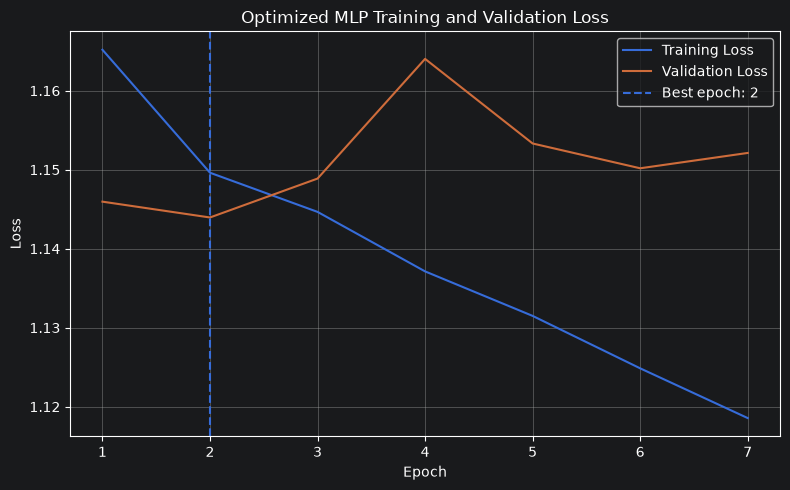

In [20]:
epochs = range(1, len(best_train_losses) + 1)

best_epoch = best_val_losses.index(
    min(best_val_losses)
) + 1

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    best_train_losses,
    label="Training Loss"
)

plt.plot(
    epochs,
    best_val_losses,
    label="Validation Loss"
)

plt.axvline(
    x=best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Optimized MLP Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "optimized_mlp_training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Odredjivanje najboljeg threshold-a na validacionom skupu.


In [21]:
best_y_val_true, best_y_val_prob = predict_probabilities(
    model=best_model,
    data_loader=optimized_val_loader,
    device=device
)

precision, recall, thresholds = precision_recall_curve(
    best_y_val_true,
    best_y_val_prob
)

denominator = precision[:-1] + recall[:-1]

f1_scores = np.divide(
    2 * precision[:-1] * recall[:-1],
    denominator,
    out=np.zeros_like(denominator),
    where=denominator != 0
)

best_index = np.argmax(f1_scores)

optimized_threshold = thresholds[best_index]
optimized_val_f1 = f1_scores[best_index]

print(
    f"Best validation threshold: "
    f"{optimized_threshold:.4f}"
)

print(
    f"Best validation F1-score: "
    f"{optimized_val_f1:.4f}"
)

Best validation threshold: 0.5558
Best validation F1-score: 0.2834


Predikcije na testu sa optimizovanim threshold-om.


In [22]:
best_y_test_true, best_y_test_prob = predict_probabilities(
    model=best_model,
    data_loader=optimized_test_loader,
    device=device
)

best_y_test_pred = (
    best_y_test_prob >= optimized_threshold
).astype(int)

 Metrike sa test skupa.

In [23]:
optimized_accuracy = accuracy_score(
    best_y_test_true,
    best_y_test_pred
)

optimized_precision = precision_score(
    best_y_test_true,
    best_y_test_pred,
    zero_division=0
)

optimized_recall = recall_score(
    best_y_test_true,
    best_y_test_pred,
    zero_division=0
)

optimized_f1 = f1_score(
    best_y_test_true,
    best_y_test_pred,
    zero_division=0
)

optimized_roc_auc = roc_auc_score(
    best_y_test_true,
    best_y_test_prob
)

print(f"Accuracy:  {optimized_accuracy:.4f}")
print(f"Precision: {optimized_precision:.4f}")
print(f"Recall:    {optimized_recall:.4f}")
print(f"F1-score:  {optimized_f1:.4f}")
print(f"ROC AUC:   {optimized_roc_auc:.4f}")

Accuracy:  0.7176
Precision: 0.1995
Recall:    0.4909
F1-score:  0.2837
ROC AUC:   0.6739


Matrica konfuzije.


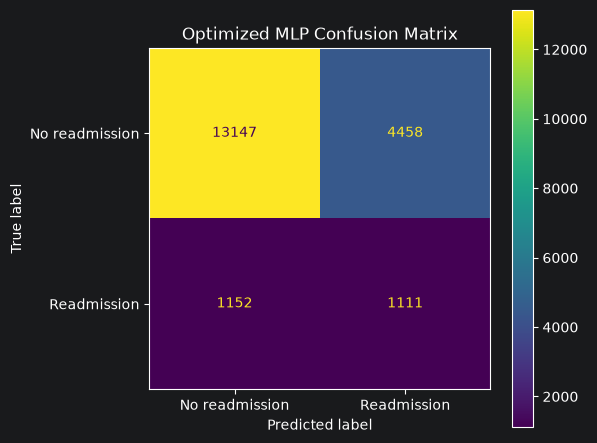

In [24]:
optimized_cm = confusion_matrix(
    best_y_test_true,
    best_y_test_pred
)

optimized_display = ConfusionMatrixDisplay(
    confusion_matrix=optimized_cm,
    display_labels=[
        "No readmission",
        "Readmission"
    ]
)

fig, ax = plt.subplots(figsize=(6, 5))

optimized_display.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Optimized MLP Confusion Matrix")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "optimized_mlp_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ROC kriva.


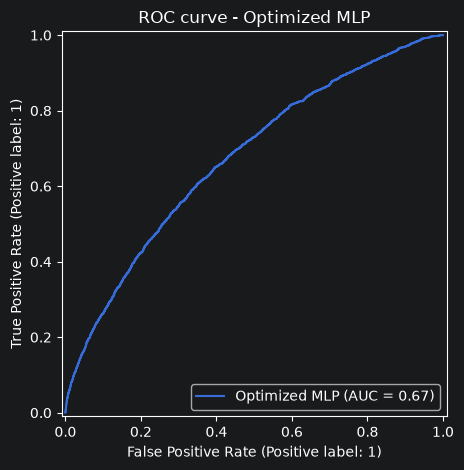

In [25]:
RocCurveDisplay.from_predictions(
    best_y_test_true,
    best_y_test_prob,
    name="Optimized MLP"
)

plt.title("ROC curve - Optimized MLP")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "optimized_mlp_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
optimized_metrics = pd.DataFrame([{
    "model": "Optimized MLP",
    "threshold": optimized_threshold,
    "accuracy": optimized_accuracy,
    "precision": optimized_precision,
    "recall": optimized_recall,
    "f1": optimized_f1,
    "roc_auc": optimized_roc_auc
}])

optimized_metrics

,model,threshold,accuracy,precision,recall,f1,roc_auc
0,Optimized MLP,0.555846,0.717636,0.199497,0.490941,0.283708,0.673922


In [27]:
optimized_metrics.to_csv(
    TABLES_DIR / "optimized_mlp_test_results.csv",
    index=False
)